In [1]:
import os
import subprocess
import sys
from pathlib import Path

SRC = Path.cwd().parent / "src"   # the notebook is in notebooks/, minimal.py is in src/

def run(script, *args):
    """Runs a script from src/, showing its output live.
    Interrupting the cell (■ button / Interrupt) kills the process and all its children."""
    cmd = [sys.executable, "-u", script, *args]   # -u: unbuffered output
    flags = subprocess.CREATE_NEW_PROCESS_GROUP if os.name == "nt" else 0
    proc = subprocess.Popen(
        cmd,
        cwd=SRC,
        stdin=subprocess.PIPE,                    # minimal.py expects input(); keep stdin open
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,                 # logging goes to stderr: merge it with stdout
        text=True,
        bufsize=1,
        creationflags=flags,
        start_new_session=(os.name != "nt"),
    )
    try:
        for line in proc.stdout:
            print(line, end="", flush=True)
        proc.wait()
    except KeyboardInterrupt:
        print("\n[Interrupted: stopping the process...]")
    finally:
        if proc.poll() is None:
            if os.name == "nt":
                subprocess.run(["taskkill", "/F", "/T", "/PID", str(proc.pid)],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            else:
                import signal
                os.killpg(proc.pid, signal.SIGKILL)
            proc.wait()
        print(f"[Process finished, exit code {proc.returncode}]")

In [5]:
import os
import sys
import subprocess
import re
import numpy as np
import matplotlib.pyplot as plt

# Detectar automáticamente si estamos dentro de /src o en la carpeta raíz
in_src = os.path.basename(os.getcwd()) == "src"
src_prefix = "" if in_src else "src/"
audio_path = "../data/Annihilator__Liquid_Oval.opus" if in_src else "data/Annihilator__Liquid_Oval.opus"

qss_values = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]

def run_experiment(script_name, qss_list, extra_args=None, time_sec=5):
    if extra_args is None:
        extra_args = []
    rates = []
    rmses = []
    snrs = []
    
    for q in qss_list:
        cmd = [
            sys.executable, f"{src_prefix}{script_name}",
            "--show_stats",
            "-t", str(time_sec),
            "-q", str(q),
            "-f", audio_path
        ] + extra_args
        
        result = subprocess.run(cmd, capture_output=True, text=True)
        out = result.stdout
        
        rate_match = re.search(r"Payload sent average = ([\d.]+)", out)
        rmse_match = re.search(r"Average RMSE \(Root Mean Square Error\) per sample = \[([\d.\s]+)\]", out)
        snr_match = re.search(r"Average SNR \(Signal Noise Ratio\) in decibels = \[([\d.\s-]+)\]", out)
        
        if rate_match and rmse_match:
            rate = float(rate_match.group(1))
            rmse_vals = [float(x) for x in rmse_match.group(1).split()]
            rmse = np.mean(rmse_vals)
            rates.append(rate)
            rmses.append(rmse)
            if snr_match:
                snr_vals = [float(x) for x in snr_match.group(1).split()]
                snrs.append(np.mean(snr_vals))
            print(f"{script_name} | Q={q:4d} -> Rate: {rate:6.1f} kbps | RMSE: {rmse:.5f}")
        else:
            print(f"Error en {script_name} con Q={q}:\n{result.stderr}")
            break
            
    return rates, rmses, snrs


--- Ejecutando stereo_MST_coding_16.py ---
stereo_MST_coding_16.py | Q=   1 -> Rate:  968.0 kbps | RMSE: 0.06399
stereo_MST_coding_16.py | Q=   2 -> Rate:  921.2 kbps | RMSE: 0.06431
stereo_MST_coding_16.py | Q=   4 -> Rate:  846.4 kbps | RMSE: 0.06469
stereo_MST_coding_16.py | Q=   8 -> Rate:  798.8 kbps | RMSE: 0.06526
stereo_MST_coding_16.py | Q=  16 -> Rate:  765.6 kbps | RMSE: 0.06790
stereo_MST_coding_16.py | Q=  32 -> Rate:  742.4 kbps | RMSE: 0.07184
stereo_MST_coding_16.py | Q=  64 -> Rate:  639.2 kbps | RMSE: 0.04894
stereo_MST_coding_16.py | Q= 128 -> Rate:  481.4 kbps | RMSE: 0.09816
stereo_MST_coding_16.py | Q= 256 -> Rate:  350.6 kbps | RMSE: 0.10004
stereo_MST_coding_16.py | Q= 512 -> Rate:  248.0 kbps | RMSE: 0.19907
stereo_MST_coding_16.py | Q=1024 -> Rate:  169.8 kbps | RMSE: 0.29512

--- Ejecutando stereo_MST_coding_32.py ---
stereo_MST_coding_32.py | Q=   1 -> Rate: 1150.8 kbps | RMSE: 0.03187
stereo_MST_coding_32.py | Q=   2 -> Rate: 1019.8 kbps | RMSE: 0.06387
ste

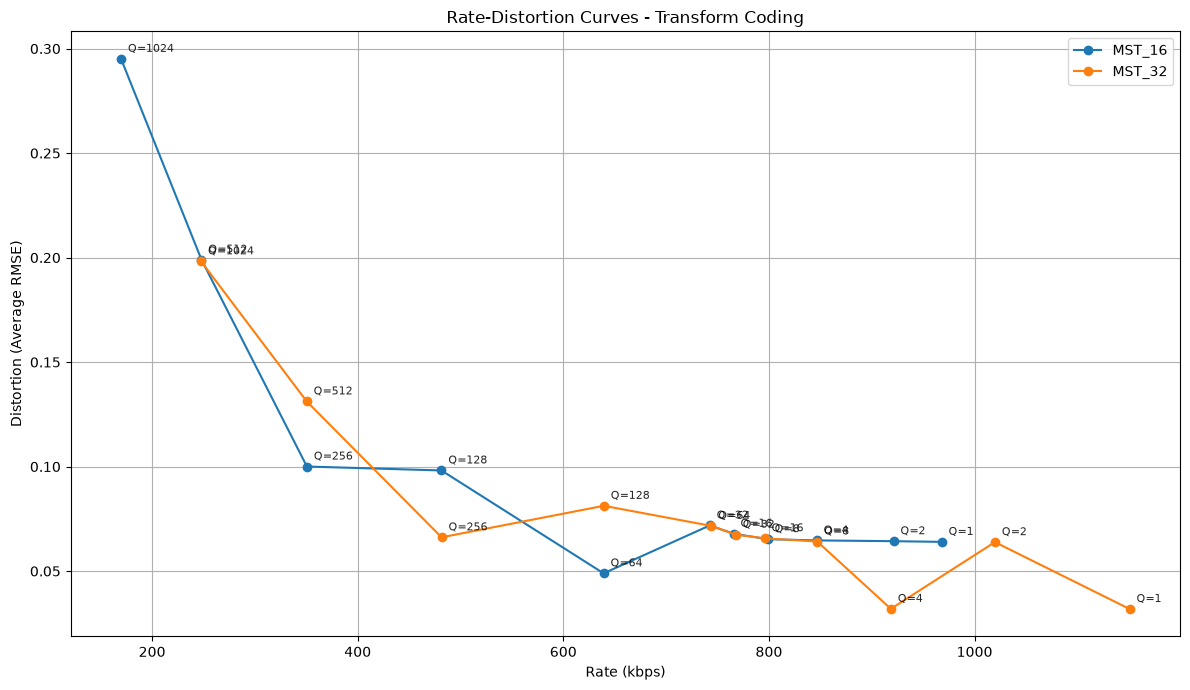

In [7]:
results = {}

print("--- Ejecutando stereo_MST_coding_16.py ---")
results["MST_16"] = run_experiment("stereo_MST_coding_16.py", qss_values)

print("\n--- Ejecutando stereo_MST_coding_32.py ---")
results["MST_32"] = run_experiment("stereo_MST_coding_32.py", qss_values)

# Dibujar la gráfica RD (Rate vs RMSE)
plt.figure(figsize=(12, 7))

for label, (rates, rmses, _) in results.items():
    plt.plot(rates, rmses, marker='o', label=label)
    
    # Añadir la etiqueta de Q a cada punto
    for q, r, rmse in zip(qss_values, rates, rmses):
        plt.annotate(
            f"Q={q}",
            (r, rmse),
            textcoords="offset points",
            xytext=(5, 5),      # Desplazamiento de 5px arriba y a la derecha para no pisar el punto
            fontsize=8,
            alpha=0.85
        )

plt.xlabel("Rate (kbps)")
plt.ylabel("Distortion (Average RMSE)")
plt.title("Rate-Distortion Curves - Transform Coding")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
